# AGENT_01 — Q-learning trong mê cung
**Bùi Anh Đức — B23DCCN165 — D23CTPM01**

Notebook thực hành learning agent: robot thử hành động, nhận reward và cập nhật bảng Q.
Bài toán và bản đồ tham khảo [GeeksforGeeks, Reinforcement Learning](https://www.geeksforgeeks.org/machine-learning/what-is-reinforcement-learning/).
Code được viết lại để có seed, giới hạn bước, log train, đánh giá độc lập và demo từ chính sách đã lưu.
Liên hệ phân loại learning agent trong [IBM, What are AI agents?](https://www.ibm.com/think/topics/ai-agents).

Chạy **Restart Kernel → Run All** từ thư mục chứa notebook. Không cần API key, GPU hoặc dữ liệu tải ngoài.
Mọi kết quả trong các ô output do mã ở notebook tạo ra.

## Bước 1 — Chuẩn bị thư viện và thư mục kết quả
NumPy lưu bảng Q và sinh số ngẫu nhiên. Matplotlib vẽ đồ thị, Pillow xuất GIF.
Seed 42 dùng cho lượt train chính. Các seed đánh giá dùng bộ sinh riêng nên không làm thay đổi lịch khám phá khi train.
Nếu chưa cài thư viện, chạy `%pip install -r requirements.txt` rồi khởi động lại kernel.

In [1]:
from pathlib import Path
from collections import deque
import csv
import json
import platform
import numpy as np
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from IPython.display import display, HTML

SEED = 42
ART = Path("artifacts")
ART.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
print(f"Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"Training seed: {SEED}")

Python 3.12.14
NumPy 2.3.5 | Matplotlib 3.11.2
Training seed: 42


## Bước 2 — Biểu diễn mê cung và luật của môi trường
Mê cung 10×10 dùng `0` cho đường đi và `1` cho vật cản, theo bản đồ của nguồn [4].
Tọa độ có dạng `(hàng, cột)`, bắt đầu từ 0. Hành động theo thứ tự trái, phải, lên, xuống.
Mỗi bước hợp lệ nhận −1; đến đích nhận +50; đâm tường hoặc ra ngoài nhận −10 và kết thúc episode.
Giới hạn 400 bước chặn trường hợp lặp không tới đích. Hết giới hạn được ghi là `timeout`.

In [2]:
maze = np.array([
    [0,1,1,1,1,1,1,1,1,1],
    [0,0,0,0,1,0,0,0,0,1],
    [1,1,1,0,1,0,1,1,0,1],
    [1,0,0,0,0,0,1,0,0,1],
    [1,0,1,1,1,1,1,0,1,1],
    [1,0,1,0,0,0,0,0,1,1],
    [1,0,1,0,1,1,1,0,1,1],
    [1,0,1,0,1,0,0,0,1,1],
    [1,0,1,0,1,0,1,0,0,1],
    [1,1,1,0,1,1,1,1,0,0],
], dtype=np.int8)
start, goal = (0, 0), (9, 9)
actions = ((0,-1), (0,1), (-1,0), (1,0))
action_names = ("LEFT", "RIGHT", "UP", "DOWN")
MAX_STEPS = 400

def valid(state):
    r, c = state
    return 0 <= r < 10 and 0 <= c < 10 and maze[r, c] == 0

def step(state, action):
    dr, dc = actions[action]
    nxt = (state[0] + dr, state[1] + dc)
    if not valid(nxt):
        return state, -10, True, "collision"
    if nxt == goal:
        return nxt, 50, True, "goal"
    return nxt, -1, False, "running"

print(f"Maze: {maze.shape}, free cells: {(maze == 0).sum()}")
print(f"Start: {start}, goal: {goal}, max steps: {MAX_STEPS}")
print("Rewards: step=-1, collision=-10, goal=+50")

Maze: (10, 10), free cells: 43
Start: (0, 0), goal: (9, 9), max steps: 400
Rewards: step=-1, collision=-10, goal=+50


## Bước 3 — Xem môi trường trước khi train
Hàm vẽ nhận vị trí hiện tại và dấu vết đã đi. Chưa có đường giải được đưa vào agent.
Ô xanh là điểm xuất phát, ngôi sao là đích, nền tối là vật cản, hình tròn cam là robot.

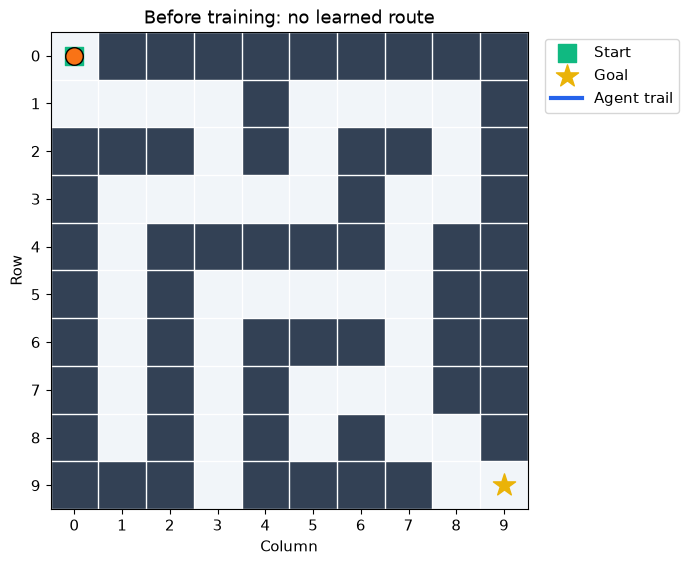

In [3]:
def draw_maze(ax, path=None, title="Maze environment"):
    ax.imshow(maze, cmap=ListedColormap(["#f1f5f9", "#334155"]))
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.scatter(start[1], start[0], s=180, c="#10b981", marker="s", label="Start")
    ax.scatter(goal[1], goal[0], s=280, c="#eab308", marker="*", label="Goal")
    if path:
        rr, cc = zip(*path)
        ax.plot(cc, rr, color="#2563eb", linewidth=3, label="Agent trail")
        ax.scatter(cc[-1], rr[-1], s=160, c="#f97316", edgecolors="black", zorder=5)
    ax.set_xlabel("Column"); ax.set_ylabel("Row")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(6.2, 6.2))
draw_maze(ax, [start], "Before training: no learned route")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.savefig(ART / "maze_before.png", dpi=180, bbox_inches="tight")
plt.show()

## Bước 4 — Chọn hành động và khởi tạo Q-learning
`Q` có kích thước 10×10×4. Mỗi giá trị ước lượng lợi ích của một hành động tại một ô.
`choose_action` dùng epsilon-greedy; khi nhiều hành động có Q bằng nhau, chọn ngẫu nhiên giữa chúng trong train.
`rollout` dùng chính sách greedy thật, không lọc hành động đâm tường và không loại ô đã ghé thăm.
Nhờ vậy, đánh giá không được trợ giúp bởi một thuật toán tìm đường bên ngoài.

In [4]:
EPISODES = 5000
ALPHA, GAMMA = 0.1, 0.9
EPS_START, EPS_MIN, EPS_DECAY = 0.5, 0.01, 0.995

def choose_action(q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(4))
    values = q[state]
    ties = np.flatnonzero(values == values.max())
    return int(rng.choice(ties))

def rollout(q, random_policy=False, seed=10000, initial=start):
    rng = np.random.default_rng(seed)
    state, path, trace, total = initial, [initial], [], 0
    for t in range(1, MAX_STEPS + 1):
        a = int(rng.integers(4)) if random_policy else int(np.argmax(q[state]))
        nxt, reward, done, status = step(state, a)
        trace.append((t, state, action_names[a], nxt, reward, status))
        path.append(nxt)
        total += reward
        state = nxt
        if done:
            return path, trace, total, status
    return path, trace, total, "timeout"

q_initial = np.zeros(maze.shape + (4,), dtype=np.float64)
print(f"Q-table: {q_initial.shape}, entries: {q_initial.size}")
print(f"Episodes={EPISODES}, alpha={ALPHA}, gamma={GAMMA}")
print(f"Epsilon: {EPS_START} -> {EPS_MIN}, decay={EPS_DECAY}")

Q-table: (10, 10, 4), entries: 400
Episodes=5000, alpha=0.1, gamma=0.9
Epsilon: 0.5 -> 0.01, decay=0.995


## Bước 5 — Train và ghi output của quá trình học
Mỗi episode khởi động lại tại `(0,0)`. Sau từng hành động, cập nhật đúng một phần tử Q.
Nếu episode kết thúc do va chạm hoặc tới đích, target chỉ gồm reward.
Giới hạn 400 bước cũng được xem là kết thúc hữu hạn của lượt chơi, nên bước cuối không bootstrap.
Log in mỗi 500 episode là trung bình trên 500 lượt vừa chạy; `eps_next` dùng cho episode kế tiếp.
Không suy ra thành công của chính sách greedy từ tỷ lệ thành công trong train có khám phá.

In [5]:
def train(seed, verbose=False):
    rng = np.random.default_rng(seed)
    q = np.zeros(maze.shape + (4,), dtype=np.float64)
    epsilon, history = EPS_START, []
    for episode in range(1, EPISODES + 1):
        state, total = start, 0
        epsilon_used = epsilon
        for t in range(1, MAX_STEPS + 1):
            a = choose_action(q, state, epsilon, rng)
            nxt, reward, done, status = step(state, a)
            terminal = done or t == MAX_STEPS
            target = reward if terminal else reward + GAMMA * q[nxt].max()
            q[state][a] += ALPHA * (target - q[state][a])
            state, total = nxt, total + reward
            if terminal:
                status = status if done else "timeout"
                break
        history.append({"episode": episode, "reward": total,
                        "steps": t, "success": int(status == "goal"),
                        "epsilon": epsilon_used, "status": status})
        epsilon = max(EPS_MIN, epsilon * EPS_DECAY)
        if verbose and episode % 500 == 0:
            block = history[-500:]
            avg_r = np.mean([x["reward"] for x in block])
            avg_s = np.mean([x["steps"] for x in block])
            rate = np.mean([x["success"] for x in block])
            print(f"Episode {episode:4d} | reward={avg_r:7.2f} | "
                  f"steps={avg_s:6.2f} | success={rate:6.1%} | eps_next={epsilon:.4f}")
    return q, history

q, history = train(SEED, verbose=True)
np.save(ART / "q_table.npy", q)
with (ART / "training_history.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=history[0].keys())
    writer.writeheader()
    writer.writerows(history)
print("Saved: artifacts/q_table.npy and training_history.csv")

Episode  500 | reward= -20.10 | steps= 11.10 | success=  0.0% | eps_next=0.0408


Episode 1000 | reward=  -4.15 | steps= 21.91 | success= 44.6% | eps_next=0.0100


Episode 1500 | reward=  20.27 | steps= 22.33 | success= 86.0% | eps_next=0.0100


Episode 2000 | reward=  20.65 | steps= 22.31 | success= 86.6% | eps_next=0.0100


Episode 2500 | reward=  21.37 | steps= 23.03 | success= 89.0% | eps_next=0.0100


Episode 3000 | reward=  20.74 | steps= 22.34 | success= 86.8% | eps_next=0.0100


Episode 3500 | reward=  21.81 | steps= 22.95 | success= 89.6% | eps_next=0.0100


Episode 4000 | reward=  20.48 | steps= 22.36 | success= 86.4% | eps_next=0.0100


Episode 4500 | reward=  20.87 | steps= 22.57 | success= 87.4% | eps_next=0.0100


Episode 5000 | reward=  20.94 | steps= 22.62 | success= 87.6% | eps_next=0.0100
Saved: artifacts/q_table.npy and training_history.csv


## Bước 6 — Vẽ reward, số bước, tỷ lệ thành công và epsilon
Ba đường đầu dùng trung bình trượt 100 episode, còn epsilon vẽ giá trị thật ở mỗi lượt.
Số bước thấp trong các lượt đầu có thể do đâm tường sớm, vì thế cần xem cùng tỷ lệ thành công.
Reward train còn dao động vì epsilon vẫn bằng 0.01 sau khi chạm mức tối thiểu.

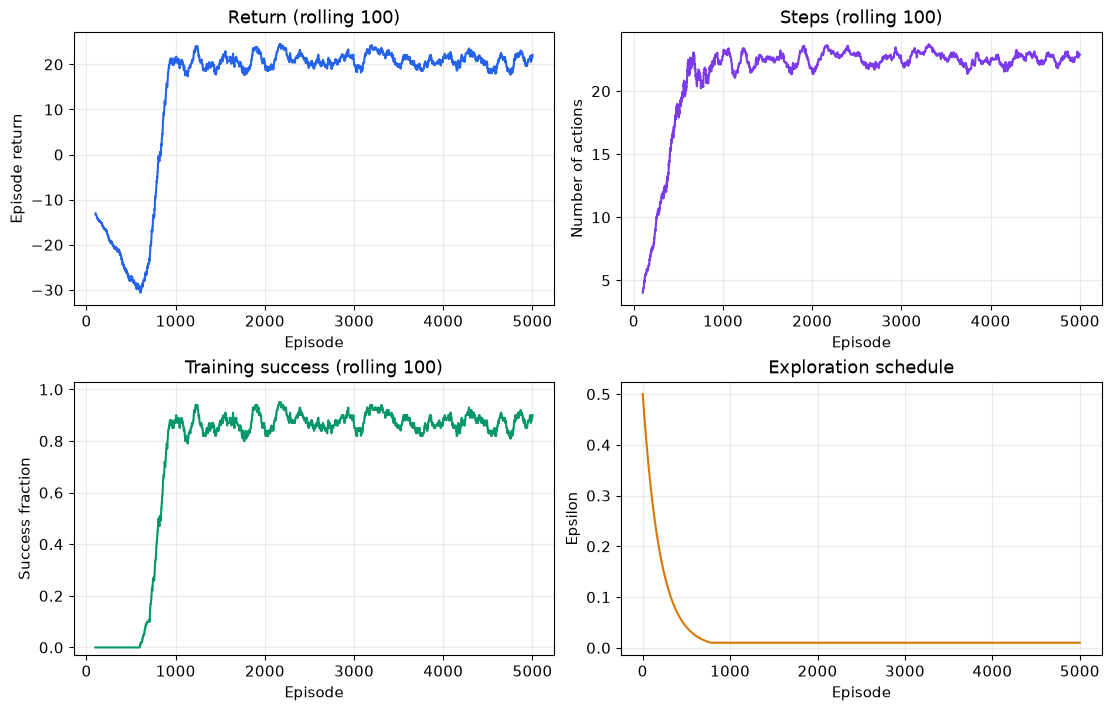

First 500: mean return=-20.10, success=0.0%
Last 500: mean return=20.94, success=87.6%


In [6]:
window = 100
def rolling(key):
    values = np.array([h[key] for h in history], dtype=float)
    return np.convolve(values, np.ones(window) / window, mode="valid")

x = np.arange(window, EPISODES + 1)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, key, title, color in zip(
    axes.flat[:3], ["reward", "steps", "success"],
    ["Return (rolling 100)", "Steps (rolling 100)", "Training success (rolling 100)"],
    ["#2563eb", "#7c3aed", "#059669"]):
    ax.plot(x, rolling(key), color=color)
    ax.set_title(title); ax.set_xlabel("Episode"); ax.grid(alpha=0.25)
axes[0, 0].set_ylabel("Episode return")
axes[0, 1].set_ylabel("Number of actions")
axes[1, 0].set_ylabel("Success fraction"); axes[1, 0].set_ylim(-0.03, 1.03)
axes[1, 1].plot([h["episode"] for h in history],
                [h["epsilon"] for h in history], color="#d97706")
axes[1, 1].set(title="Exploration schedule", xlabel="Episode", ylabel="Epsilon")
axes[1, 1].grid(alpha=0.25)
fig.savefig(ART / "learning_curves.png", dpi=200)
plt.show()
for label, block in [("First 500", history[:500]), ("Last 500", history[-500:])]:
    print(f"{label}: mean return={np.mean([h['reward'] for h in block]):.2f}, "
          f"success={np.mean([h['success'] for h in block]):.1%}")

## Bước 7 — Đánh giá chính sách và đối chiếu BFS
BFS chỉ dùng sau train để tính số bước ngắn nhất, không tham gia chọn hành động hoặc cập nhật Q.
So sánh 3 chính sách trên cùng bản đồ và điểm xuất phát: Q bằng 0, hành động ngẫu nhiên, Q đã train.
Đánh giá 1000 episode cho mỗi chính sách. Với greedy tất định, 1000 lượt giống nhau;
đây là kiểm tra trên môi trường đã học, không phải 1000 tình huống mới.

In [7]:
def shortest_path(initial=start):
    queue = deque([(initial, [initial])])
    seen = {initial}
    while queue:
        state, path = queue.popleft()
        if state == goal:
            return path
        for dr, dc in actions:
            nxt = (state[0] + dr, state[1] + dc)
            if valid(nxt) and nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return []

optimal = shortest_path()
path, trace, total, status = rollout(q)
results = []
print("Policy                 Success     Mean return    Mean steps")
for name, table, random_policy in [
    ("Untrained greedy", q_initial, False),
    ("Random", q_initial, True),
    ("Trained greedy", q, False)]:
    runs = [rollout(table, random_policy, 10000 + i) for i in range(1000)]
    row = {"policy": name, "episodes": 1000,
           "success_rate": float(np.mean([r[3] == "goal" for r in runs])),
           "mean_return": float(np.mean([r[2] for r in runs])),
           "mean_steps": float(np.mean([len(r[1]) for r in runs]))}
    results.append(row)
    print(f"{name:<22} {row['success_rate']:7.1%} "
          f"{row['mean_return']:15.3f} {row['mean_steps']:13.3f}")
print(f"BFS shortest path: {len(optimal)-1} actions")
print(f"Trained path: {len(trace)} actions, return={total}, terminal={status}")
assert status == "goal"
assert len(trace) == len(optimal) - 1
assert all(valid(s) for s in path)
assert total == 50 - (len(trace) - 1)
print("Checks passed: goal reached, valid path, BFS length, reward total.")

Policy                 Success     Mean return    Mean steps
Untrained greedy          0.0%         -10.000         1.000


Random                    0.0%         -10.530         1.530


Trained greedy          100.0%          27.000        24.000
BFS shortest path: 24 actions
Trained path: 24 actions, return=27, terminal=goal
Checks passed: goal reached, valid path, BFS length, reward total.


## Bước 8 — Kiểm tra thêm các seed và các ô xuất phát
Chạy lại toàn bộ quá trình train với 5 seed cố định để xem kết quả có phụ thuộc riêng seed 42 hay không.
Ngoài điểm đầu đã train, đánh giá greedy từ mọi ô trống không phải đích trên cùng bản đồ.
Các ô này không phải một tập bản đồ test độc lập; một số ô có thể đã xuất hiện trong quá trình khám phá.
Nếu không tới đích, giữ nguyên thất bại trong kết quả.

In [8]:
seed_rows = []
print("Seed   Status       Actions   Return   Gap to BFS")
for seed in [0, 7, 21, 42, 99]:
    q_seed, _ = train(seed)
    p, tr, ret, end = rollout(q_seed)
    gap = len(tr) - (len(optimal) - 1) if end == "goal" else None
    seed_rows.append({"seed": seed, "status": end, "steps": len(tr),
                      "return": ret, "gap_to_bfs": gap})
    print(f"{seed:4d}   {end:<10} {len(tr):7d} {ret:8d}   {gap}")
starts = [tuple(map(int, s)) for s in np.argwhere(maze == 0)
          if tuple(s) != goal]
start_runs = [rollout(q, initial=s) for s in starts]
start_successes = sum(r[3] == "goal" for r in start_runs)
failed_starts = [s for s, r in zip(starts, start_runs) if r[3] != "goal"]
print(f"All free starts: {start_successes}/{len(starts)} reached the goal")
print(f"Failed starts: {failed_starts}")

Seed   Status       Actions   Return   Gap to BFS


   0   goal            24       27   0


   7   goal            24       27   0


  21   goal            24       27   0


  42   goal            24       27   0


  99   goal            24       27   0
All free starts: 27/42 reached the goal
Failed starts: [(3, 1), (4, 1), (5, 1), (5, 3), (5, 4), (5, 5), (6, 1), (6, 3), (7, 1), (7, 3), (7, 5), (8, 1), (8, 3), (8, 5), (9, 3)]


## Bước 9 — Demo tác tử tự chạy bằng bảng Q đã lưu
Đọc lại `q_table.npy`, không gọi `train` và không dùng BFS trong demo.
Mỗi bước chọn `argmax Q(state)`, thực thi môi trường rồi ghi lại hành động.
Ảnh tổng hợp lấy các thời điểm trong chính rollout này; GIF chứa đầy đủ các bước.

Reloaded Q: (10, 10, 4)
Step | State    | Action | Next     | Reward | Status
   1 | (0, 0)   | DOWN   | (1, 0)   |     -1 | running
   2 | (1, 0)   | RIGHT  | (1, 1)   |     -1 | running
   3 | (1, 1)   | RIGHT  | (1, 2)   |     -1 | running
   4 | (1, 2)   | RIGHT  | (1, 3)   |     -1 | running
   5 | (1, 3)   | DOWN   | (2, 3)   |     -1 | running
   6 | (2, 3)   | DOWN   | (3, 3)   |     -1 | running
   7 | (3, 3)   | RIGHT  | (3, 4)   |     -1 | running
   8 | (3, 4)   | RIGHT  | (3, 5)   |     -1 | running
   9 | (3, 5)   | UP     | (2, 5)   |     -1 | running
  10 | (2, 5)   | UP     | (1, 5)   |     -1 | running
  11 | (1, 5)   | RIGHT  | (1, 6)   |     -1 | running
  12 | (1, 6)   | RIGHT  | (1, 7)   |     -1 | running
  13 | (1, 7)   | RIGHT  | (1, 8)   |     -1 | running
  14 | (1, 8)   | DOWN   | (2, 8)   |     -1 | running
  15 | (2, 8)   | DOWN   | (3, 8)   |     -1 | running
  16 | (3, 8)   | LEFT   | (3, 7)   |     -1 | running
  17 | (3, 7)   | DOWN   | (4, 7)   |     

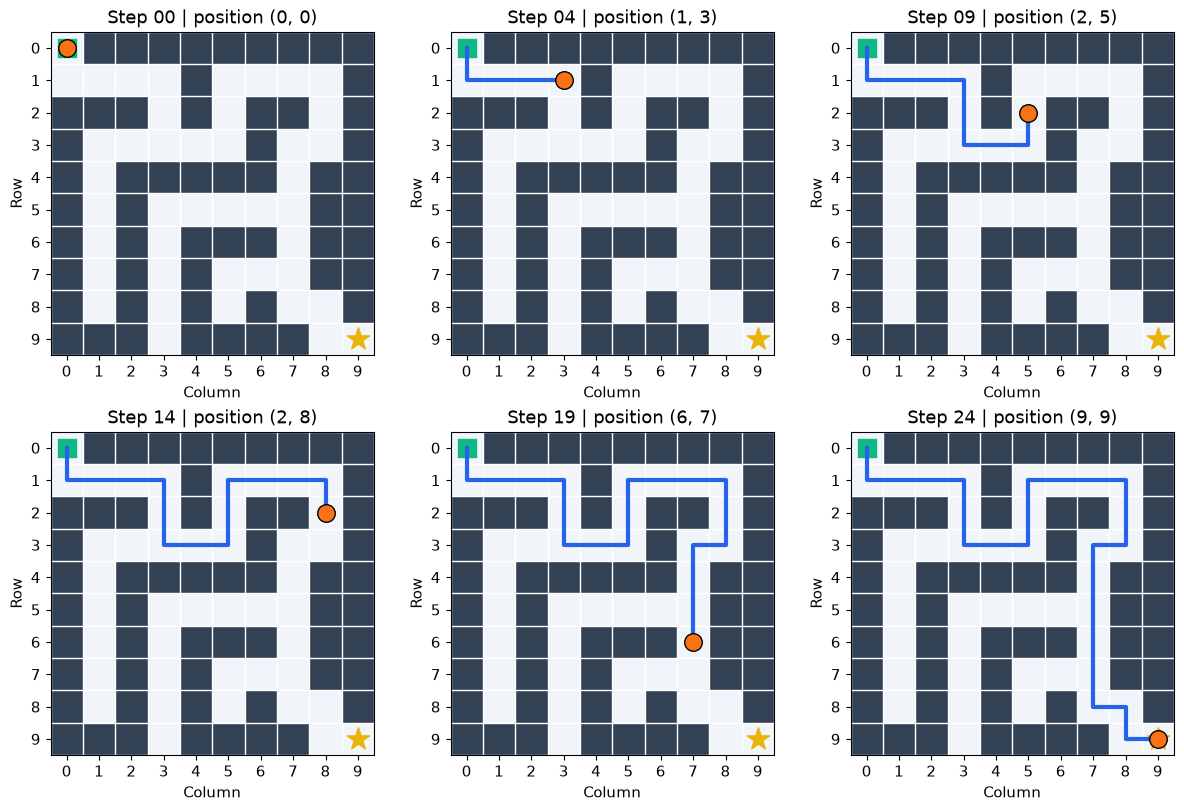

In [9]:
q_saved = np.load(ART / "q_table.npy", allow_pickle=False)
demo_path, demo_trace, demo_return, demo_status = rollout(q_saved)
assert np.array_equal(q_saved, q)
assert demo_status == "goal"
print(f"Reloaded Q: {q_saved.shape}")
print("Step | State    | Action | Next     | Reward | Status")
for t, s, a, nxt, r, end in demo_trace:
    print(f"{t:4d} | {str(s):8} | {a:6} | {str(nxt):8} | {r:6d} | {end}")
print(f"Demo finished: {demo_status}, actions={len(demo_trace)}, return={demo_return}")

indices = np.linspace(0, len(demo_path) - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for ax, i in zip(axes.flat, indices):
    draw_maze(ax, demo_path[:i+1], f"Step {i:02d} | position {demo_path[i]}")
fig.savefig(ART / "demo_contact_sheet.png", dpi=200)
plt.show()

## Bước 10 — Xuất GIF, đồ thị so sánh và dữ liệu để kiểm tra lại
GIF được vẽ từ vị trí robot trong rollout thật, không phải hoạt ảnh đường đi được điền thủ công.
Biểu đồ so sánh phải đọc cùng bảng kết quả: chính sách ngẫu nhiên có thể ít bước vì thất bại sớm.
Tệp JSON lưu cấu hình, số liệu, đường đi và phiên bản thư viện; CSV lưu toàn bộ lịch sử train và demo.

In [10]:
frames = []
for i in range(len(demo_path)):
    fig, ax = plt.subplots(figsize=(5.4, 5.4))
    draw_maze(ax, demo_path[:i+1], f"Trained Q-learning agent | step {i:02d}")
    fig.tight_layout()
    fig.canvas.draw()
    rgba = np.asarray(fig.canvas.buffer_rgba())
    frames.append(Image.fromarray(rgba.copy()).convert("RGB"))
    plt.close(fig)
frames[0].save(ART / "agent_demo.gif", save_all=True,
               append_images=frames[1:] + [frames[-1]] * 6,
               duration=180, loop=0)
display(HTML('<img src="artifacts/agent_demo.gif" alt="Agent after training" width="500">'))
print(f"Saved GIF from {len(demo_path)} rollout positions.")

Saved GIF from 25 rollout positions.


### So sánh các chính sách
Đồ thị dùng đúng các kết quả 1000 lượt đánh giá ở Bước 7.

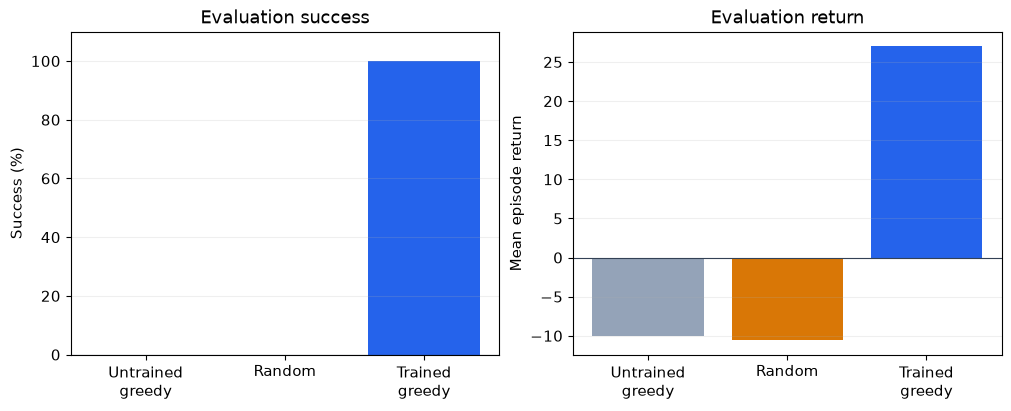

Saved: artifacts/policy_comparison.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
names = [r["policy"].replace(" ", "\n") for r in results]
colors = ["#94a3b8", "#d97706", "#2563eb"]
axes[0].bar(names, [100*r["success_rate"] for r in results], color=colors)
axes[0].set(title="Evaluation success", ylabel="Success (%)", ylim=(0, 110))
axes[1].bar(names, [r["mean_return"] for r in results], color=colors)
axes[1].set(title="Evaluation return", ylabel="Mean episode return")
for ax in axes:
    ax.axhline(0, color="#334155", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
fig.savefig(ART / "policy_comparison.png", dpi=200)
plt.show()
print("Saved: artifacts/policy_comparison.png")

### Lưu dữ liệu kết quả
Giữ CSV và JSON cùng notebook để có thể đối chiếu số liệu trong báo cáo.

In [12]:
with (ART / "demo_trace.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["step", "state", "action", "next_state", "reward", "status"])
    writer.writerows(demo_trace)
summary = {"config": {"seed": SEED, "episodes": EPISODES, "alpha": ALPHA,
           "gamma": GAMMA, "epsilon_start": EPS_START, "epsilon_min": EPS_MIN,
           "epsilon_decay": EPS_DECAY, "max_steps": MAX_STEPS},
           "versions": {"python": platform.python_version(), "numpy": np.__version__,
                        "matplotlib": matplotlib.__version__},
           "evaluation": results, "seed_checks": seed_rows,
           "bfs_steps": len(optimal)-1, "demo_steps": len(demo_trace),
           "demo_return": demo_return, "demo_status": demo_status,
           "demo_path": demo_path, "all_starts_total": len(starts),
           "all_starts_success": start_successes, "failed_starts": failed_starts,
           "first500_return": float(np.mean([h["reward"] for h in history[:500]])),
           "last500_return": float(np.mean([h["reward"] for h in history[-500:]])),
           "first500_success": float(np.mean([h["success"] for h in history[:500]])),
           "last500_success": float(np.mean([h["success"] for h in history[-500:]]))}
(ART / "results.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved: agent_demo.gif, policy_comparison.png, demo_trace.csv, results.json")

Saved: agent_demo.gif, policy_comparison.png, demo_trace.csv, results.json


## Nhận xét và giới hạn
- Reward được đọc cùng trạng thái kết thúc; số bước ngắn không có ý nghĩa nếu agent đâm tường.
- BFS xác minh độ dài đường đi sau train. Việc gọi hàm này không làm thay đổi Q hoặc chính sách.
- Greedy từ cùng điểm đầu trong môi trường tất định sẽ lặp lại cùng một đường đi.
- Năm seed và các ô xuất phát bổ sung chỉ kiểm tra trên bản đồ hiện tại, chưa đo khả năng giải bản đồ mới.
- Nếu thay bản đồ hoặc cách tính reward, cần train và đánh giá lại; không dùng con số cũ cho cấu hình mới.

## Nguồn
1. [Google Cloud — What are AI agents?](https://cloud.google.com/discover/what-are-ai-agents)
2. [IBM — What are AI agents?](https://www.ibm.com/think/topics/ai-agents)
3. [McKinsey — What is an AI agent?](https://www.mckinsey.com/featured-insights/mckinsey-explainers/what-is-an-ai-agent)
4. [GeeksforGeeks — Reinforcement Learning](https://www.geeksforgeeks.org/machine-learning/what-is-reinforcement-learning/)